# VERITAS AI — Pipeline de PLN para identificação de padrões associados a notícias falsas

**Disciplina:** Processamento de Linguagem Natural (PLN) · **Grupo:** *[preencher nomes dos integrantes]* · **Professor:** *[preencher]*

Este notebook implementa, de ponta a ponta, o pipeline que alimenta a aplicação web **VERITAS AI**: carregamento do *Fake.br Corpus*, análise de qualidade, pré-processamento, vetorização TF-IDF, treinamento e comparação de modelos, avaliação em teste isolado, explicabilidade e exportação dos artefatos (`modelo_veritas.joblib`, `metricas.json`, `metadata.json`).

> **Aviso metodológico.** O sistema **não verifica fatos**. Ele aprende padrões linguísticos de um conjunto de notícias rotuladas e estima a qual classe (FAKE ou TRUE) um texto se assemelha. Uma notícia verdadeira escrita em estilo sensacionalista pode ser rotulada como FAKE, e o contrário também.

## 2. Objetivo científico

**Pergunta de pesquisa:** *é possível distinguir, usando apenas características textuais (TF-IDF) e classificadores lineares clássicos, notícias rotuladas como falsas e verdadeiras em português do Brasil? E o quanto desse desempenho decorre de atalhos do conjunto de dados (tamanho do texto, fonte, formatação) e não de linguagem?*

Objetivos específicos: (i) auditar a qualidade do corpus; (ii) comparar configurações de TF-IDF; (iii) comparar Regressão Logística, Naive Bayes e SVM linear; (iv) avaliar em um teste isolado com métricas por classe; (v) interpretar coeficientes; (vi) medir a sensibilidade a vieses do corpus; (vii) exportar um pipeline único usado pela aplicação.

## 3. Importação das bibliotecas

Dependências (Python 3.10+): `pip install -r ../requirements.txt`. No Google Colab, execute `!pip install scikit-learn pandas numpy matplotlib joblib flask` e envie as pastas `veritas/` e `data/` para o ambiente.

In [1]:
import sys, os, json, re, warnings, datetime, platform, time
sys.path.insert(0, os.path.abspath('..'))          # permite `import veritas`
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, joblib, sklearn
from collections import Counter
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, roc_auc_score, brier_score_loss, f1_score)
from sklearn.calibration import calibration_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from veritas import (build_pipeline, load_dataset, top_terms, explain, normalize_text, preprocess_text,
                     STOPWORDS_PT, MAX_WORDS, Analyzer)

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
FIG_DIR = '../docs/figs'; os.makedirs(FIG_DIR, exist_ok=True)
COLORS = {'FAKE': '#d9485f', 'TRUE': '#1a8fb3'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{name}.png', dpi=170, bbox_inches='tight'); plt.show()

print('Python', platform.python_version(), '| scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

Python 3.12.3 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4


## 4. Carregamento da base

**Base:** *Fake.br Corpus* (Monteiro et al., 2018) — notícias em português brasileiro publicadas principalmente entre 2015 e 2018, 3.600 falsas e 3.600 verdadeiras, com alinhamento por tema (as verdadeiras foram selecionadas para corresponder às falsas) e arquivos de metadados (autor, link, categoria, data, métricas linguísticas). Os arquivos foram fornecidos pelo grupo em `data/full_texts/` (ver `data/README.md`; a licença deve ser conferida no repositório original antes de redistribuir os dados).

In [2]:
DATA_DIR = '../data/full_texts'
assert os.path.isdir(DATA_DIR), 'Coloque o Fake.br Corpus em data/full_texts (ver data/README.md)'
df = load_dataset(DATA_DIR)
print('Registros:', len(df))
print(df.label.value_counts().to_string())
df.head(3)[['id', 'label', 'category', 'date', 'link']]

Registros: 7200
label
FAKE    3600
TRUE    3600


   id label             category        date                                                                                                                                    link
0   1  FAKE             politica  2017-11-30          https://ceticismopolitico.com/2017/11/30/katia-abreu-diz-que-vai-colocar-sua-expulsao-em-uma-moldura-mas-nao-para-de-reclamar/
1   2  FAKE  sociedade_cotidiano  2017-11-28         https://ceticismopolitico.com/2017/11/28/blog-esquerdista-da-a-entender-que-reclamar-de-dedada-no-futebol-e-sinal-de-homofobia/
2   3  FAKE             politica  2017-11-28  https://ceticismopolitico.com/2017/11/28/alckmin-diz-que-por-ele-psdb-desembarca-mas-nao-explica-se-utilizara-o-aparelho-do-filme-mib/

## 5. Exploração dos dados

In [3]:
df['domain'] = df.link.str.extract(r'https?://([^/]+)')[0]
df['year'] = df.date.astype(str).str.extract(r'((?:19|20)\d\d)')[0]
df['n_words_raw'] = df.text.str.split().str.len()

print('--- Categorias por classe ---')
print(pd.crosstab(df.category, df.label).to_string())
print('\n--- Principais domínios de origem por classe ---')
for lab in ['FAKE', 'TRUE']:
    vc = df[df.label == lab].domain.value_counts()
    print(lab, '| nº de domínios:', len(vc)); print((vc.head(5) / len(df[df.label == lab]) * 100).round(1).astype(str).add('%').to_string(), '\n')
print('--- Ano de publicação (extraído de `date`) ---')
print(pd.crosstab(df.year, df.label).to_string())

--- Categorias por classe ---
label                FAKE  TRUE
category                       
ciencia_tecnologia     56    56
economia               22    22
politica             2090  2090
religiao               22    22
sociedade_cotidiano   638   638
tv_celebridades       772   772

--- Principais domínios de origem por classe ---
FAKE | nº de domínios: 5
domain
www.diariodobrasil.org        92.7%
afolhabrasil.com.br            4.8%
www.thejornalbrasil.com.br     1.8%
ceticismopolitico.com          0.4%
www.topfivetv.com              0.2% 

TRUE | nº de domínios: 24
domain
g1.globo.com                    63.9%
politica.estadao.com.br         20.9%
internacional.estadao.com.br     3.2%
cultura.estadao.com.br           2.6%
www1.folha.uol.com.br            2.5% 

--- Ano de publicação (extraído de `date`) ---
label  FAKE  TRUE
year             
2009      0     3
2010      0     6
2011      0     5
2012      1     9
2013      0     5
2014      0    10
2015    235    40
2016   1586   27

**Leitura crítica.** O corpus é perfeitamente balanceado e alinhado por categoria — o que é bom —, mas as fontes são muito concentradas: a grande maioria das FAKE vem de poucos sites e as TRUE vêm sobretudo de dois grandes portais. Isso cria o risco de o modelo aprender *estilo editorial/fonte* em vez de *desinformação*. Voltaremos a isso na seção 6 e na análise de robustez (seção 17).

## 6. Análise de qualidade (vazios, duplicatas, vazamento e artefatos)

In [4]:
print('Textos vazios :', int((df.text.str.strip() == '').sum()))
print('Duplicatas exatas (texto bruto):', int(df.duplicated('text').sum()))
df['norm'] = df.text.map(normalize_text)
print('Duplicatas após normalização   :', int(df.duplicated('norm').sum()))

# Artefatos que revelam o rótulo sem ter relação com linguagem
art = {
    'BOM (\\ufeff) no início': df.text.str.startswith('\ufeff'),
    'aspas curvas (“ ”)': df.text.str.contains('[“”]', regex=True),
    'contém URL': df.text.str.contains('http', regex=False),
    'menciona "g1"': df.norm.str.contains(r'\bg1\b', regex=True),
}
tab = pd.DataFrame({k: v.groupby(df.label).mean().mul(100).round(1) for k, v in art.items()}).T
tab.columns = [f'% {c}' for c in tab.columns]
print('\n--- Artefatos de coleta/formatação (porcentagem de textos) ---'); print(tab.to_string())
print('\n--- Palavras por texto (bruto) ---'); print(df.groupby('label').n_words_raw.describe().round(0).to_string())

Textos vazios : 0
Duplicatas exatas (texto bruto): 1
Duplicatas após normalização   : 1

--- Artefatos de coleta/formatação (porcentagem de textos) ---
                        % FAKE  % TRUE
BOM (\ufeff) no início     0.0     0.3
aspas curvas (“ ”)         0.0    57.8
contém URL                 0.2     2.9
menciona "g1"              1.0    21.8

--- Palavras por texto (bruto) ---
        count    mean    std   min    25%    50%     75%     max
label                                                           
FAKE   3600.0   186.0  128.0   9.0  115.0  157.0   224.0  2288.0
TRUE   3600.0  1100.0  683.0  20.0  642.0  918.0  1416.0  7517.0


In [5]:
# Quase-duplicatas (textos derivados da mesma notícia): similaridade do cosseno entre TF-IDF dos textos
Xq = TfidfVectorizer(min_df=2, dtype=np.float32).fit_transform(df.norm)
labels = df.label.values
near_pairs = []
for s in range(0, Xq.shape[0], 1000):
    S = (Xq[s:s+1000] @ Xq.T).toarray()
    for r in range(S.shape[0]):
        i = s + r
        for j in np.where(S[r] >= 0.90)[0]:
            if j > i: near_pairs.append((i, j))
cross = sum(labels[i] != labels[j] for i, j in near_pairs)
print(f'Pares com similaridade >= 0,90: {len(near_pairs)} (entre classes diferentes: {cross})')

Pares com similaridade >= 0,90: 67 (entre classes diferentes: 0)


**Achados da auditoria** (valores acima): (1) há poucas ou nenhuma duplicata; (2) aspas curvas, BOM e menção a "g1" aparecem quase só nas TRUE — são **artefatos de coleta** que um modelo exploraria como atalho; (3) as TRUE são ~6× mais longas — o **tamanho** sozinho já separa muito as classes. Medidas adotadas: normalizar aspas/BOM/URLs, truncar todos os textos às primeiras 200 palavras, remover duplicatas e quase-duplicatas *antes* da divisão e quantificar o efeito de cada decisão (ablação, seção 17).

## 7. Pré-processamento

Etapas (módulo `veritas/preprocess.py`, **o mesmo usado pela aplicação**): minúsculas → normalização Unicode (NFKC) → aspas/travessões tipográficos para ASCII → remoção de BOM, caracteres de controle e URLs → colapso de espaços → truncamento a 200 palavras. **Não** removemos pontuação (`!` e `?` são mantidos como tokens), negações (*não, nem, nunca, sem*) nem acentos; a remoção de stopwords é tratada como hiperparâmetro (lista própria, sem negações).

In [6]:
ex = df[df.label == 'TRUE'].text.iloc[0][:260]
print('ANTES :', repr(ex)); print('DEPOIS:', repr(preprocess_text(ex, None)))

# remoção de duplicatas exatas (pós-normalização) e quase-duplicatas (mantém a 1ª ocorrência)
drop = set(df.index[df.duplicated('norm')])
for i, j in near_pairs: drop.add(df.index[j])
df_clean = df.drop(index=sorted(drop)).reset_index(drop=True)
print(f'\nRemovidos: {len(drop)} (duplicatas/quase-duplicatas) -> {len(df_clean)} notícias restantes')
print(df_clean.label.value_counts().to_string())

ANTES : '\ufeffO Podemos decidiu  expulsar o deputado federal Carlos Gaguim do partido após a Polícia Federal fazer buscas a apreensões no gabinete dele na Câmara. Com isso, a legenda abre espaço para receber a senadora expulsa pelo PMDB, Katia Abreu. Por meio de nota, a le'
DEPOIS: 'o podemos decidiu expulsar o deputado federal carlos gaguim do partido após a polícia federal fazer buscas a apreensões no gabinete dele na câmara. com isso, a legenda abre espaço para receber a senadora expulsa pelo pmdb, katia abreu. por meio de nota, a le'

Removidos: 63 (duplicatas/quase-duplicatas) -> 7137 notícias restantes
label
FAKE    3592
TRUE    3545


## 8. Análise exploratória textual

        count    mean    std   min    25%    50%     75%     max
label                                                           
FAKE   3592.0   185.5  127.2   9.0  115.0  157.0   224.0  2286.0
TRUE   3545.0  1099.5  685.6  20.0  639.0  914.0  1416.0  7517.0


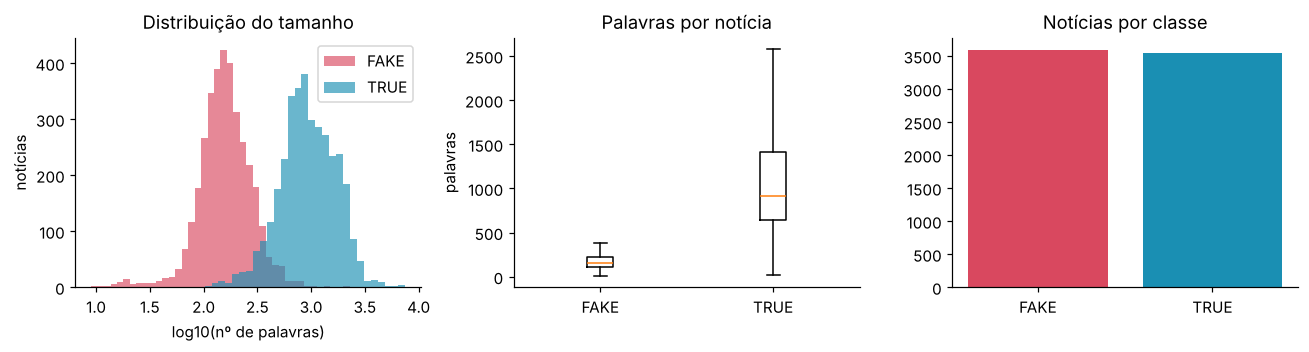

In [7]:
df_clean['n_words'] = df_clean.norm.str.split().str.len()
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for lab in ['FAKE', 'TRUE']:
    ax[0].hist(np.log10(df_clean[df_clean.label == lab].n_words), bins=40, alpha=.65, color=COLORS[lab], label=lab)
ax[0].set_xlabel('log10(nº de palavras)'); ax[0].set_ylabel('notícias'); ax[0].legend(); ax[0].set_title('Distribuição do tamanho')
ax[1].boxplot([df_clean[df_clean.label == l].n_words.clip(upper=3000) for l in ['FAKE', 'TRUE']], showfliers=False); ax[1].set_xticklabels(['FAKE', 'TRUE'])
ax[1].set_ylabel('palavras'); ax[1].set_title('Palavras por notícia')
cnt = df_clean.label.value_counts()
ax[2].bar(cnt.index, cnt.values, color=[COLORS[i] for i in cnt.index]); ax[2].set_title('Notícias por classe')
savefig('fig_eda_tamanho')
print(df_clean.groupby('label').n_words.describe().round(1).to_string())

{'FAKE': ['não', 'lula', 'presidente', 'disse', 'dilma', 'brasil', 'país', 'temer', 'governo', 'federal'], 'TRUE': ['não', 'presidente', 'lula', 'anos', 'disse', 'federal', 'governo', 'segundo', 'temer', 'brasil']}

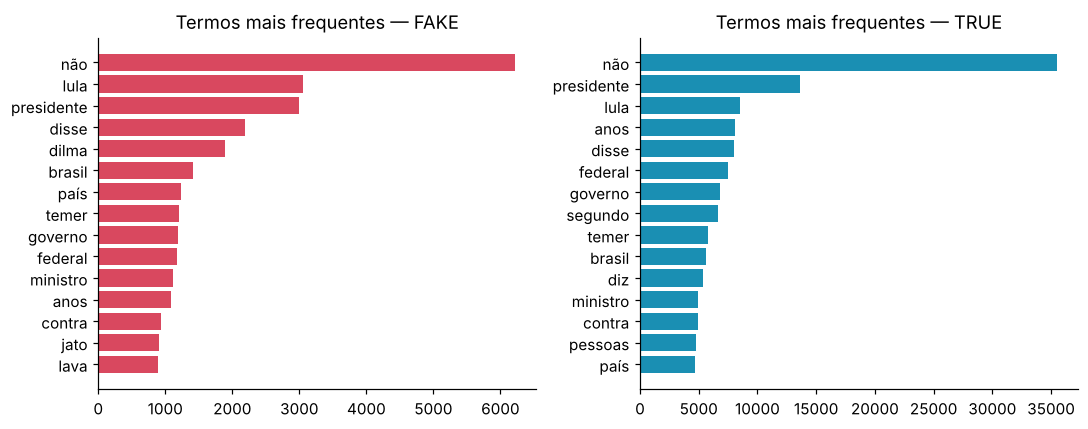

In [8]:
tok = lambda s: re.findall(r'\w+', s)
sw = set(STOPWORDS_PT)
freq = {lab: Counter(w for t in df_clean[df_clean.label == lab].norm for w in tok(t) if w not in sw and len(w) > 2) for lab in COLORS}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, lab in zip(ax, COLORS):
    words, vals = zip(*freq[lab].most_common(15)); a.barh(words[::-1], vals[::-1], color=COLORS[lab]); a.set_title(f'Termos mais frequentes — {lab}')
savefig('fig_eda_termos')
{lab: [w for w, _ in freq[lab].most_common(10)] for lab in freq}

## 9. Vetorização TF-IDF

O **TF-IDF** representa cada texto como um vetor esparso em que cada dimensão é um termo (unigrama ou n-grama): `tf` mede quantas vezes o termo aparece no texto (usamos `sublinear_tf`, i.e. 1 + log tf) e `idf = log(N/df)` reduz o peso de termos presentes em quase todos os documentos. Parâmetros: `ngram_range` (contexto local: bigramas capturam "não é", "segundo o"), `min_df` (descarta termos raros), `max_df` (descarta termos onipresentes), `max_features` (limita o vocabulário). **Para evitar vazamento, o TF-IDF é sempre ajustado (`fit`) apenas no conjunto de treino**, dentro do `Pipeline`; a comparação de configurações é feita na seção 11, depois da divisão.

In [9]:
toy = ['o governo não aprovou a medida', 'o governo aprovou a medida', 'urgente compartilhe antes que apaguem']
v = TfidfVectorizer(ngram_range=(1, 2), token_pattern=r'(?u)\b\w+\b').fit(toy)
pd.DataFrame(v.transform(toy).toarray(), columns=v.get_feature_names_out()).round(2).loc[:, ['não', 'não aprovou', 'aprovou', 'urgente', 'o']]

    não  não aprovou  aprovou  urgente     o
0  0.36         0.36     0.28     0.00  0.28
1  0.00         0.00     0.32     0.00  0.32
2  0.00         0.00     0.00     0.33  0.00

## 10. Separação dos conjuntos

Divisão **estratificada** 70% treino / 15% validação / 15% teste (semente fixa). A duplicação já foi removida antes da divisão. O **teste só é usado na seção 14** (e para o relatório pós-seleção); toda escolha de hiperparâmetros usa treino/validação.

In [10]:
trainval, test = train_test_split(df_clean, test_size=0.15, stratify=df_clean.label, random_state=SEED)
train, val = train_test_split(trainval, test_size=0.15 / 0.85, stratify=trainval.label, random_state=SEED)
split_info = {n: {'n': len(d), **d.label.value_counts().to_dict()} for n, d in [('treino', train), ('validação', val), ('teste', test)]}
print(pd.DataFrame(split_info).T.to_string())
assert not (set(train.norm) & set(test.norm)) and not (set(train.norm) & set(val.norm)) and not (set(val.norm) & set(test.norm))
print('OK: nenhum texto compartilhado entre treino, validação e teste.')
Xtr, ytr, Xva, yva, Xte, yte = train.text, train.label, val.text, val.label, test.text, test.label

              n  FAKE  TRUE
treino     4995  2514  2481
validação  1071   539   532
teste      1071   539   532
OK: nenhum texto compartilhado entre treino, validação e teste.


## 11. Treinamento dos modelos

### 11.1 Configurações de vetorização
Usamos Regressão Logística (C=10) com validação cruzada estratificada de 3 dobras **no treino**, métrica **F1 macro** (média do F1 das duas classes).

In [11]:
vec_grid = {
    'unigramas, min_df=3':               dict(ngram=(1, 1), min_df=3, max_df=0.9, max_features=50000),
    'uni+bigramas, min_df=3':            dict(ngram=(1, 2), min_df=3, max_df=0.9, max_features=50000),
    'uni+bigramas, min_df=3, stopwords': dict(ngram=(1, 2), min_df=3, max_df=0.9, max_features=50000, stopwords=True),
    'uni+bigramas, min_df=5':            dict(ngram=(1, 2), min_df=5, max_df=0.9, max_features=50000),
    'uni+bigramas, max_df=0.5':          dict(ngram=(1, 2), min_df=3, max_df=0.5, max_features=50000),
    'uni+bigramas, max_features=20000':  dict(ngram=(1, 2), min_df=3, max_df=0.9, max_features=20000),
}
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
vec_res = []
for name, kw in vec_grid.items():
    t0 = time.time()
    s = cross_val_score(build_pipeline('logreg', C=10, **kw), Xtr, ytr, cv=cv3, scoring='f1_macro')
    vec_res.append({'config': name, 'f1_macro_cv': round(s.mean(), 4), 'desvio': round(s.std(), 4), 'seg': round(time.time() - t0, 1)})
vec_df = pd.DataFrame(vec_res); print(vec_df.to_string(index=False))
best_vec_name = vec_df.sort_values('f1_macro_cv', ascending=False).iloc[0].config
BEST_VEC = vec_grid[best_vec_name]; print('\nConfiguração escolhida:', best_vec_name, BEST_VEC)

                           config  f1_macro_cv  desvio  seg
              unigramas, min_df=3       0.9235  0.0082 15.1
           uni+bigramas, min_df=3       0.9353  0.0055 20.2
uni+bigramas, min_df=3, stopwords       0.9255  0.0064 18.6
           uni+bigramas, min_df=5       0.9349  0.0064 19.4
         uni+bigramas, max_df=0.5       0.9335  0.0057 20.7
 uni+bigramas, max_features=20000       0.9327  0.0061 20.0

Configuração escolhida: uni+bigramas, min_df=3 {'ngram': (1, 2), 'min_df': 3, 'max_df': 0.9, 'max_features': 50000}


### 11.2 Modelos e hiperparâmetros
Três classificadores sobre a mesma vetorização: **Regressão Logística** (principal), **Multinomial Naive Bayes** (baseline) e **Linear SVM** (opcional). O hiperparâmetro de regularização de cada um é escolhido pelo F1 macro na **validação**.

In [12]:
model_grid = {'logreg': ('Regressão Logística', [1, 10, 100]), 'nb': ('Multinomial Naive Bayes', [0.03, 0.1, 0.5]), 'svm': ('Linear SVM', [0.3, 1, 3])}
tuning, fitted = [], {}
for key, (pt, Cs) in model_grid.items():
    for C in Cs:
        t0 = time.time(); p = build_pipeline(key, C=C, **BEST_VEC).fit(Xtr, ytr); fit_s = time.time() - t0
        pr = p.predict(Xva)
        tuning.append({'modelo': pt, 'key': key, 'C/alpha': C, 'acc_val': accuracy_score(yva, pr), 'f1_macro_val': f1_score(yva, pr, average='macro'), 'fit_seg': round(fit_s, 1)})
        fitted[(key, C)] = p
tun = pd.DataFrame(tuning); print(tun.drop(columns='key').round(4).to_string(index=False))
best_per_model = tun.sort_values('f1_macro_val', ascending=False).groupby('key').head(1).set_index('key')
print('\nMelhor hiperparâmetro por modelo:'); print(best_per_model[['modelo', 'C/alpha', 'f1_macro_val']].round(4).to_string())

                 modelo  C/alpha  acc_val  f1_macro_val  fit_seg
    Regressão Logística     1.00   0.9290        0.9290      7.1
    Regressão Logística    10.00   0.9468        0.9468      7.1
    Regressão Logística   100.00   0.9468        0.9468      7.6
Multinomial Naive Bayes     0.03   0.8880        0.8879      6.9
Multinomial Naive Bayes     0.10   0.8889        0.8889      6.9
Multinomial Naive Bayes     0.50   0.8786        0.8786      7.0
             Linear SVM     0.30   0.9421        0.9421      7.1
             Linear SVM     1.00   0.9477        0.9477      6.9
             Linear SVM     3.00   0.9458        0.9458      6.7

Melhor hiperparâmetro por modelo:
                         modelo  C/alpha  f1_macro_val
key                                                   
svm                  Linear SVM      1.0        0.9477
logreg      Regressão Logística    100.0        0.9468
nb      Multinomial Naive Bayes      0.1        0.8889


## 12. Comparação dos resultados
Para cada modelo (com o melhor hiperparâmetro) calculamos precisão, recall e F1 por classe na validação e a média ± desvio do F1 macro em validação cruzada de 3 dobras no treino.

                 Modelo  Acc (val)  F1 macro (val)  Prec. FAKE  Rec. FAKE F1 macro CV (média±dp)
             Linear SVM     0.9477          0.9477      0.9583     0.9369        0.9357 ± 0.0044
    Regressão Logística     0.9468          0.9468      0.9513     0.9425        0.9347 ± 0.0041
Multinomial Naive Bayes     0.8889          0.8889      0.8962     0.8813        0.8772 ± 0.0062


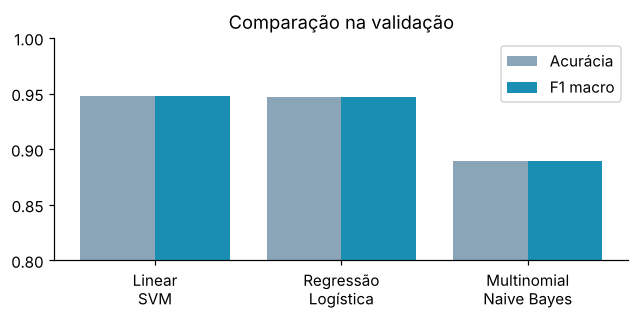

In [13]:
def metrics_dict(y, pred):
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=['FAKE', 'TRUE'], zero_division=0)
    return {'accuracy': float(accuracy_score(y, pred)), 'f1_macro': float(f1_score(y, pred, average='macro')),
            'precision_macro': float(p.mean()), 'recall_macro': float(r.mean()),
            'per_class': {c: {'precision': float(p[i]), 'recall': float(r[i]), 'f1': float(f[i]), 'support': int(s[i])} for i, c in enumerate(['FAKE', 'TRUE'])}}

comparison = []
for key, row in best_per_model.iterrows():
    C = row['C/alpha']; p = fitted[(key, C)]
    cv = cross_val_score(build_pipeline(key, C=C, **BEST_VEC), Xtr, ytr, cv=cv3, scoring='f1_macro')
    comparison.append({'key': key, 'model': row.modelo, 'param': float(C), 'val': metrics_dict(yva, p.predict(Xva)),
                       'cv_f1_macro_mean': float(cv.mean()), 'cv_f1_macro_std': float(cv.std()), 'fit_seconds': float(row.fit_seg)})
cmp_df = pd.DataFrame([{'Modelo': c['model'], 'Acc (val)': c['val']['accuracy'], 'F1 macro (val)': c['val']['f1_macro'],
                        'Prec. FAKE': c['val']['per_class']['FAKE']['precision'], 'Rec. FAKE': c['val']['per_class']['FAKE']['recall'],
                        'F1 macro CV (média±dp)': f"{c['cv_f1_macro_mean']:.4f} ± {c['cv_f1_macro_std']:.4f}"} for c in comparison])
print(cmp_df.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 3)); x = np.arange(len(comparison))
ax.bar(x - .2, [c['val']['accuracy'] for c in comparison], .4, label='Acurácia', color='#8aa4b8')
ax.bar(x + .2, [c['val']['f1_macro'] for c in comparison], .4, label='F1 macro', color=COLORS['TRUE'])
ax.set_xticks(x); ax.set_xticklabels([c['model'].replace(' ', '\n', 1) for c in comparison]); ax.set_ylim(.8, 1); ax.legend(); ax.set_title('Comparação na validação')
savefig('fig_comparacao_modelos')

## 13. Seleção do modelo

**Critério explícito:** (1) F1 macro na validação e em validação cruzada — não só acurácia; (2) **a Regressão Logística é o modelo principal**, e só é substituída se outro modelo superar seu F1 macro de validação em **mais de 1 ponto percentual** (diferenças menores estão dentro da variação esperada); (3) a Regressão Logística fornece probabilidades e coeficientes interpretáveis, requisito do produto.

In [14]:
by_key = {c['key']: c for c in comparison}
lr, others = by_key['logreg'], [c for c in comparison if c['key'] != 'logreg']
challenger = max(others, key=lambda c: c['val']['f1_macro'])
if challenger['val']['f1_macro'] - lr['val']['f1_macro'] > 0.01: sel = challenger
else: sel = lr
SELECTED_KEY, SELECTED_C = sel['key'], sel['param']
print(f"LR F1 val={lr['val']['f1_macro']:.4f} | melhor alternativa ({challenger['model']}) F1 val={challenger['val']['f1_macro']:.4f}")
print('Modelo selecionado:', sel['model'], '| C/alpha =', SELECTED_C)
final_pipe = fitted[(SELECTED_KEY, SELECTED_C if SELECTED_KEY != 'logreg' else int(SELECTED_C))]
assert SELECTED_KEY == 'logreg', 'O app (probabilidades/explicabilidade) pressupõe Regressão Logística.'

LR F1 val=0.9468 | melhor alternativa (Linear SVM) F1 val=0.9477
Modelo selecionado: Regressão Logística | C/alpha = 100.0


## 14. Avaliação no conjunto de teste

Primeira e única avaliação do modelo selecionado no **teste isolado**. Classe positiva para erros = **FAKE** (alvo da detecção): *falso negativo* = FAKE classificada como TRUE; *falso positivo* = TRUE classificada como FAKE.

In [15]:
pred_te = final_pipe.predict(Xte)
proba_te = final_pipe.predict_proba(Xte)
classes = list(final_pipe.named_steps['clf'].classes_); i_fake = classes.index('FAKE')
test_m = metrics_dict(yte, pred_te)
print(f"Acurácia no teste: {test_m['accuracy']:.4f} | F1 macro: {test_m['f1_macro']:.4f} (n={len(test)})")

Acurácia no teste: 0.9505 | F1 macro: 0.9505 (n=1071)


## 15. Matriz de confusão

Linhas = classe real; colunas = classe predita (FAKE, TRUE)
 [[503  36]
 [ 17 515]]


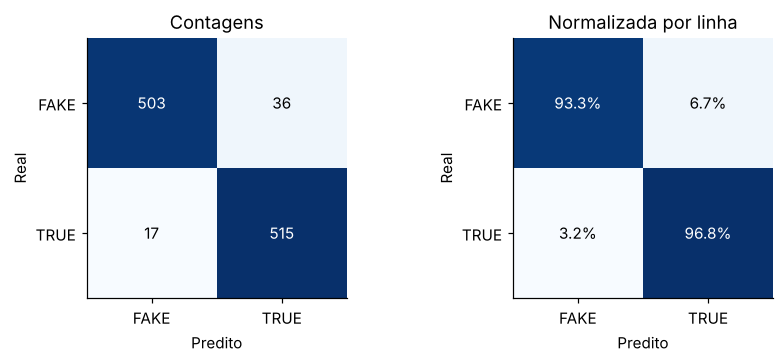

In [16]:
cm = confusion_matrix(yte, pred_te, labels=['FAKE', 'TRUE'])
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
for a, M, t, fmt in [(ax[0], cm, 'Contagens', '{:d}'), (ax[1], cm / cm.sum(1, keepdims=True), 'Normalizada por linha', '{:.1%}')]:
    a.imshow(M, cmap='Blues'); a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(['FAKE', 'TRUE']); a.set_yticklabels(['FAKE', 'TRUE'])
    a.set_xlabel('Predito'); a.set_ylabel('Real'); a.set_title(t)
    for i in range(2):
        for j in range(2): a.text(j, i, fmt.format(M[i, j]), ha='center', va='center', color='white' if M[i, j] > M.max() / 2 else 'black')
savefig('fig_matriz_confusao')
print('Linhas = classe real; colunas = classe predita (FAKE, TRUE)\n', cm)

## 16. Precision, Recall, F1 e Accuracy — por classe, calibração e análise de erros

              precision    recall  f1-score   support

        FAKE     0.9673    0.9332    0.9500       539
        TRUE     0.9347    0.9680    0.9511       532

    accuracy                         0.9505      1071
   macro avg     0.9510    0.9506    0.9505      1071
weighted avg     0.9511    0.9505    0.9505      1071

ROC-AUC=0.9920 | Brier=0.0373 | ECE=0.0271
  faixa   n  confianca_media  acuracia
0.5-0.6  36            0.548     0.667
0.6-0.7  45            0.645     0.600
0.7-0.8  64            0.759     0.828
0.8-0.9  96            0.856     0.906
0.9-1.0 830            0.980     0.996


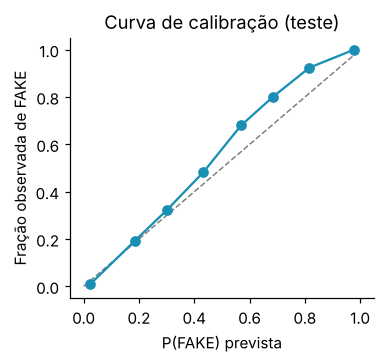

In [17]:
print(classification_report(yte, pred_te, digits=4))
auc = roc_auc_score((yte == 'FAKE').astype(int), proba_te[:, i_fake])
brier = brier_score_loss((yte == 'FAKE').astype(int), proba_te[:, i_fake])
# ECE (confiança da classe prevista x acerto), 10 faixas
conf = proba_te.max(1); correct = (pred_te == yte.values).astype(float)
bins = np.linspace(.5, 1, 6); ece = 0.0; cal_bins = []
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (conf >= lo) & (conf <= hi if hi == 1 else conf < hi)
    if m.sum(): cal_bins.append({'faixa': f'{lo:.1f}-{hi:.1f}', 'n': int(m.sum()), 'confianca_media': float(conf[m].mean()), 'acuracia': float(correct[m].mean())}); ece += m.sum() / len(conf) * abs(correct[m].mean() - conf[m].mean())
print(f'ROC-AUC={auc:.4f} | Brier={brier:.4f} | ECE={ece:.4f}')
print(pd.DataFrame(cal_bins).round(3).to_string(index=False))
frac, mean_p = calibration_curve((yte == 'FAKE').astype(int), proba_te[:, i_fake], n_bins=8)
plt.figure(figsize=(3.6, 3.4)); plt.plot([0, 1], [0, 1], '--', color='gray', lw=1); plt.plot(mean_p, frac, 'o-', color=COLORS['TRUE'])
plt.xlabel('P(FAKE) prevista'); plt.ylabel('Fração observada de FAKE'); plt.title('Curva de calibração (teste)')
savefig('fig_calibracao')

In [18]:
err = test.assign(pred=pred_te, p_fake=proba_te[:, i_fake])
fn = err[(err.label == 'FAKE') & (err.pred == 'TRUE')]; fp = err[(err.label == 'TRUE') & (err.pred == 'FAKE')]
print(f'Falsos negativos (FAKE -> TRUE): {len(fn)} | Falsos positivos (TRUE -> FAKE): {len(fp)}')
print('\nTamanho mediano (palavras): acertos =', int(err[err.label == err.pred].n_words.median()), '| erros =', int(err[err.label != err.pred].n_words.median()))
print('\nTaxa de erro por categoria:'); print(err.assign(erro=err.label != err.pred).groupby('category').erro.agg(['mean', 'count']).round(3).to_string())
for nome, d in [('FALSO NEGATIVO', fn), ('FALSO POSITIVO', fp)]:
    for _, r in d.head(2).iterrows(): print(f"\n[{nome}] p(FAKE)={r.p_fake:.2f} | {r.norm[:230]}...")

Falsos negativos (FAKE -> TRUE): 36 | Falsos positivos (TRUE -> FAKE): 17

Tamanho mediano (palavras): acertos = 362 | erros = 356

Taxa de erro por categoria:
                      mean  count
category                         
ciencia_tecnologia   0.130     23
economia             0.111      9
politica             0.050    604
religiao             0.111      9
sociedade_cotidiano  0.038    182
tv_celebridades      0.045    244

[FALSO NEGATIVO] p(FAKE)=0.35 | cni se reúne com temer e sugere jornada de trabalho de 80 horas semanais (corrigido). após uma reunião com o presidente interino michel temer, robson braga [presidente da confederação nacional da indústria] disse que serão necessá...

[FALSO NEGATIVO] p(FAKE)=0.40 | pessoas que se arrepiam ao ouvir músicas têm um cérebro especial. um grupo de cientistas de harvard, liderado pelo pesquisador matthew sachs, realizou uma pesquisa para descobrir como a música é capaz de afetar o corpo humano. é c...

[FALSO POSITIVO] p(FAKE)=0.63 | a

**Como ler o erro.** Em detecção de desinformação os dois erros têm custos distintos: um *falso negativo* deixa passar uma notícia falsa; um *falso positivo* sinaliza indevidamente conteúdo legítimo (risco reputacional). Por isso reportamos precision e recall **por classe**, e não apenas a acurácia.

**Calibração.** As probabilidades da Regressão Logística *não* são calibradas formalmente (não aplicamos Platt/isotônica); a tabela e a curva acima mostram o quanto se aproximam da frequência observada **neste corpus de teste** — o que não garante o mesmo comportamento em notícias de outras fontes e épocas.

## 17. Explicabilidade e robustez a vieses

{'FAKE': ['!', 'dilma', 'lula', 'através', 'poderá', 'hoje', 'está', 'disse', 'coréia', 'coréia do', 'informou', 'acordo com'], 'TRUE': ['feira', 'nesta', 'mas', 'diz', 'segundo', 'g1', 'no', 'na', 'como', 'terça', 'em', 'quarta']}

Identidade aditiva: 5.91853 == 5.91853

Termos de fonte/estilo no vocabulário (coef > 0 => TRUE): {'g1': 10.25, 'globo': -5.08, 'estadão': -0.81, 'folha': -3.37, 'diário': -3.69, '!': -20.02, 'urgente': -3.96}


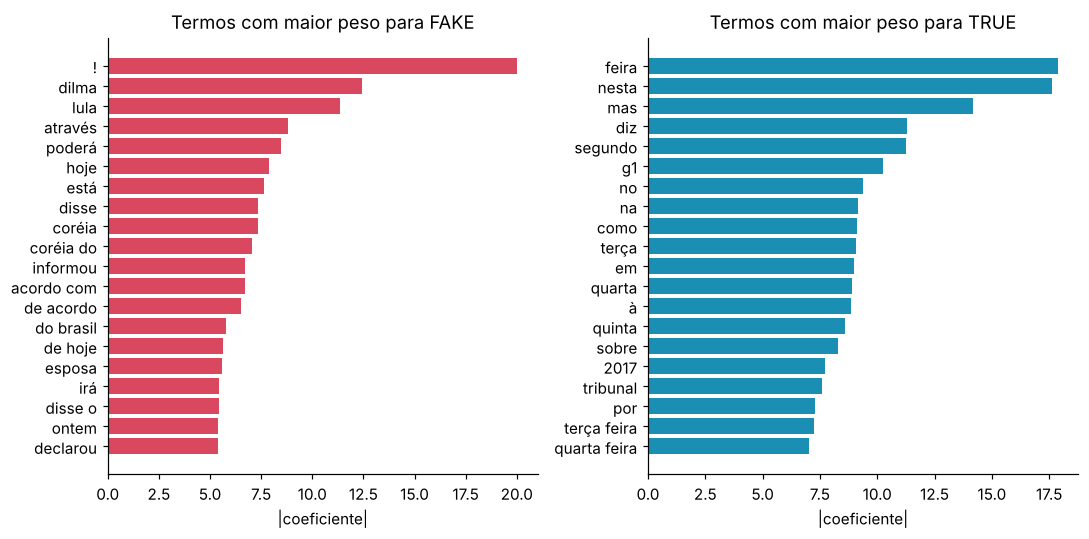

In [19]:
tt = top_terms(final_pipe, 20)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, lab in zip(ax, ['FAKE', 'TRUE']):
    terms, w = zip(*tt[lab]); a.barh(list(terms)[::-1], [abs(x) for x in w][::-1], color=COLORS[lab]); a.set_title(f'Termos com maior peso para {lab}'); a.set_xlabel('|coeficiente|')
savefig('fig_termos_coeficientes')
print({lab: [t for t, _ in tt[lab][:12]] for lab in tt})
# Verificação: soma das contribuições + intercepto == função de decisão
x0 = Xte.iloc[0]; e0 = explain(final_pipe, x0, k=10**6)
tot = sum(w for lab in ('FAKE', 'TRUE') for _, w in e0[lab]) + e0['intercept']
print('\nIdentidade aditiva:', round(tot, 6), '==', round(float(final_pipe.decision_function([x0])[0]), 6))
# Termos relacionados à FONTE/formatação presentes no vocabulário
vocab = {t: i for i, t in enumerate(final_pipe.named_steps['tfidf'].get_feature_names_out())}
coef = final_pipe.named_steps['clf'].coef_[0]
print('\nTermos de fonte/estilo no vocabulário (coef > 0 => TRUE):', {t: round(float(coef[vocab[t]]), 2) for t in ['g1', 'globo', 'estadão', 'folha', 'diário', '!', 'urgente', 'compartilhe'] if t in vocab})

**Limites da interpretação.** Coeficientes mostram **associações estatísticas aprendidas neste corpus**, não causalidade nem prova de falsidade: termos como "feira", "nesta", "segundo" (jornalismo factual de agências/portais) ou "g1" (nome do portal de origem das TRUE) indicam que o modelo aprende **estilo e fonte**. Nenhum termo isolado comprova desinformação.

In [20]:
# --- Robustez 1: ablação do pré-processamento (validação, LR C=10) ---
abl = []
for nome, kw in [('texto bruto (só minúsculas), sem truncar', dict(mode='raw', max_words=None)),
                 ('normalizado, sem truncar',                 dict(mode='full', max_words=None)),
                 ('normalizado + truncado em 200 (adotado)', dict(mode='full', max_words=200)),
                 ('normalizado + truncado em 100',            dict(mode='full', max_words=100))]:
    p = build_pipeline('logreg', C=10, ngram=BEST_VEC['ngram'], min_df=BEST_VEC['min_df'], max_df=BEST_VEC['max_df'], max_features=BEST_VEC['max_features'], stopwords=BEST_VEC.get('stopwords', False), **kw).fit(Xtr, ytr)
    pr = p.predict(Xva); abl.append({'variante': nome, 'acc_val': round(accuracy_score(yva, pr), 4), 'f1_macro_val': round(f1_score(yva, pr, average='macro'), 4)})
abl_df = pd.DataFrame(abl); print(abl_df.to_string(index=False))

# --- Robustez 2: classificador usando APENAS o tamanho do texto (nº de palavras brutas) ---
f = lambda d: np.log1p(d.text.str.split().str.len()).values.reshape(-1, 1)
len_clf = LogisticRegression().fit(f(train), ytr); pl = len_clf.predict(f(val))
len_only = {'acc_val': round(accuracy_score(yva, pl), 4), 'f1_macro_val': round(f1_score(yva, pl, average='macro'), 4)}
print('\nBaseline só com tamanho do texto (sem truncar):', len_only)

                                variante  acc_val  f1_macro_val
texto bruto (só minúsculas), sem truncar   0.9645        0.9645
                normalizado, sem truncar   0.9617        0.9617
 normalizado + truncado em 200 (adotado)   0.9468        0.9468
           normalizado + truncado em 100   0.9281        0.9281

Baseline só com tamanho do texto (sem truncar): {'acc_val': 0.9412, 'f1_macro_val': 0.9412}


In [21]:
# --- Robustez 3: generalização entre fontes (experimento separado; não usa o teste principal) ---
# treino: FAKE do domínio dominante + TRUE do portal dominante; teste: FAKE e TRUE de OUTROS domínios
top_fake = df_clean[df_clean.label == 'FAKE'].domain.value_counts().index[0]
top_true = df_clean[df_clean.label == 'TRUE'].domain.value_counts().index[0]
in_a = ((df_clean.label == 'FAKE') & (df_clean.domain == top_fake)) | ((df_clean.label == 'TRUE') & (df_clean.domain == top_true))
A, B = df_clean[in_a], df_clean[~in_a]
pA = build_pipeline('logreg', C=SELECTED_C, **BEST_VEC).fit(A.text, A.label); prB = pA.predict(B.text)
rec = {c: float((prB[B.label.values == c] == c).mean()) for c in ['FAKE', 'TRUE']}
source_holdout = {'train_domains': [top_fake, top_true], 'n_train': int(len(A)), 'n_test': int(len(B)), 'n_test_fake': int((B.label == 'FAKE').sum()), 'n_test_true': int((B.label == 'TRUE').sum()),
                  'recall_FAKE': rec['FAKE'], 'recall_TRUE': rec['TRUE'], 'accuracy': float(accuracy_score(B.label, prB))}
print(source_holdout)

{'train_domains': ['www.diariodobrasil.org', 'g1.globo.com'], 'n_train': 5591, 'n_test': 1546, 'n_test_fake': 263, 'n_test_true': 1283, 'recall_FAKE': 0.5817490494296578, 'recall_TRUE': 0.8222915042868277, 'accuracy': 0.7813712807244502}


**Interpretação da robustez.** A ablação mostra quanto do desempenho depende de artefatos (tamanho, aspas, BOM); o baseline de tamanho mostra o poder de um atalho trivial; e o teste entre fontes (treinar em um par de portais e testar em outros) mede a generalização além do estilo editorial das fontes dominantes. Qualquer queda nesses cenários indica que as métricas do teste principal **superestimam** o desempenho em notícias de fontes diferentes.

## 18. Testes com notícias de exemplo

In [22]:
# Textos DEMONSTRATIVOS escritos para teste (não pertencem ao corpus e não possuem rótulo oficial).
exemplos = {
 'estilo sensacionalista (sintético)': 'URGENTE!!! Compartilhe antes que apaguem! Políticos tentam esconder a verdade e a mídia não quer que você saiba o que aconteceu hoje. Divulgue para todos os seus contatos, o Brasil precisa acordar!',
 'estilo factual de agência (sintético)': 'O Ministério da Fazenda informou nesta quarta-feira que a arrecadação federal cresceu no trimestre, segundo dados divulgados pela Receita. De acordo com o órgão, o resultado foi puxado pela retomada da atividade econômica, mas a pasta não detalhou projeções para os próximos meses.',
}
def analisar_mem(t):
    p = final_pipe.predict_proba([t])[0]; return dict(zip(classes, np.round(p, 3)))
for k, t in exemplos.items(): print(f'{k}: {analisar_mem(t)}')
print('\nCasos de borda:')
for nome, t in [('vazio', ''), ('só espaços', '   '), ('muito curto', 'oi'), ('emojis/símbolos', '🔥🔥 ### @@@ !!! ???'), ('não-português', 'The president said on Tuesday that the new policy will be announced soon.')]:
    try: print(f'  {nome:16s}', analisar_mem(t) if normalize_text(t) else 'entrada vazia: o app bloqueia o envio')
    except Exception as e: print(f'  {nome:16s} erro:', e)

estilo sensacionalista (sintético): {'FAKE': np.float64(1.0), 'TRUE': np.float64(0.0)}
estilo factual de agência (sintético): {'FAKE': np.float64(0.048), 'TRUE': np.float64(0.952)}

Casos de borda:
  vazio            entrada vazia: o app bloqueia o envio
  só espaços       entrada vazia: o app bloqueia o envio
  muito curto      {'FAKE': np.float64(0.99), 'TRUE': np.float64(0.01)}
  emojis/símbolos  {'FAKE': np.float64(1.0), 'TRUE': np.float64(0.0)}
  não-português    {'FAKE': np.float64(0.957), 'TRUE': np.float64(0.043)}


*Observação:* o resultado dos exemplos sintéticos é apenas ilustrativo do comportamento do modelo; **não** constitui avaliação de desempenho (que é feita exclusivamente no conjunto de teste, seção 14).

## 19. Exportação do modelo

In [23]:
MODEL_DIR = '../model'; os.makedirs(MODEL_DIR, exist_ok=True)
trained_at = datetime.datetime.now().astimezone().isoformat(timespec='seconds')
joblib.dump(final_pipe, f'{MODEL_DIR}/modelo_veritas.joblib', compress=3)
metadata = {
    'model_name': 'Regressão Logística + TF-IDF', 'version': '1.0.0', 'trained_at': trained_at, 'dataset': 'Fake.br Corpus',
    'classes': classes, 'positive_class_for_errors': 'FAKE', 'max_words': MAX_WORDS, 'random_state': SEED,
    'vectorizer_config': {**{k: (list(v) if isinstance(v, tuple) else v) for k, v in BEST_VEC.items()}, 'sublinear_tf': True, 'token_pattern': r'(?u)\b\w+\b|[!?]'},
    'model_hyperparameters': {'C': SELECTED_C, 'class_weight': 'balanced', 'max_iter': 2000},
    'selection_rule': 'F1 macro na validação; Regressão Logística preferida salvo superioridade > 1 p.p. de outro modelo',
    'library_versions': {'python': platform.python_version(), 'scikit-learn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'joblib': joblib.__version__},
    'training_set_size': int(len(train)), 'probabilities_calibrated': False,
    'disclaimer': 'Classificação de padrões linguísticos aprendidos em corpus rotulado; não é verificação factual.'}
json.dump(metadata, open(f'{MODEL_DIR}/metadata.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print(os.listdir(MODEL_DIR), '| tamanho do modelo: %.2f MB' % (os.path.getsize(f'{MODEL_DIR}/modelo_veritas.joblib') / 1e6))

['modelo_veritas.joblib', 'metadata.json'] | tamanho do modelo: 0.97 MB


## 20. Exportação das métricas

As métricas abaixo são lidas pelo dashboard da aplicação e usadas no artigo — **nenhum número é digitado à mão**. Após a gravação, o modelo é recarregado do disco e comparado com o da memória.

In [24]:
# Comparação pós-hoc dos três modelos no TESTE (apenas após a seleção, para o relatório)
for c in comparison:
    p = fitted[(c['key'], int(c['param']) if c['key'] == 'logreg' and float(c['param']).is_integer() else c['param'])]
    c['test'] = metrics_dict(yte, p.predict(Xte))
metricas = {
  'generated_at': trained_at, 'version': metadata['version'],
  'dataset': {'name': 'Fake.br Corpus', 'n_raw': int(len(df)), 'n_removed_duplicates': int(len(drop)), 'n_clean': int(len(df_clean)),
              'class_counts_clean': df_clean.label.value_counts().to_dict(), 'class_counts_raw': df.label.value_counts().to_dict(),
              'split': split_info, 'words_by_class': df_clean.groupby('label').n_words.describe().round(1).to_dict('index'),
              'artifacts_pct': tab.to_dict(), 'near_duplicate_pairs_ge_0.90': int(len(near_pairs)),
              'top_domains': {l: df[df.label == l].domain.value_counts(normalize=True).head(3).round(3).to_dict() for l in ['FAKE', 'TRUE']}},
  'vectorization_experiments': vec_df.to_dict('records'), 'selected_vectorization': {'name': best_vec_name, **{k: (list(v) if isinstance(v, tuple) else v) for k, v in BEST_VEC.items()}},
  'model_comparison': comparison, 'selected_model': {'key': SELECTED_KEY, 'name': 'Regressão Logística', 'C': SELECTED_C},
  'test': {**test_m, 'n': int(len(test)), 'labels': ['FAKE', 'TRUE'], 'confusion_matrix': cm.tolist(), 'roc_auc': float(auc), 'brier': float(brier), 'ece': float(ece), 'calibration_bins': cal_bins},
  'errors': {'false_negatives_fake_as_true': int(len(fn)), 'false_positives_true_as_fake': int(len(fp)), 'median_words_correct': int(err[err.label == err.pred].n_words.median()), 'median_words_errors': int(err[err.label != err.pred].n_words.median())},
  'top_terms': {k: [{'term': t, 'weight': w} for t, w in v] for k, v in tt.items()},
  'robustness': {'preprocessing_ablation_val': abl_df.to_dict('records'), 'length_only_baseline_val': len_only, 'source_holdout': source_holdout},
}
json.dump(metricas, open(f'{MODEL_DIR}/metricas.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
# verificação de reprodutibilidade: recarrega do disco e compara com o modelo em memória
an = Analyzer(MODEL_DIR)
assert (an.pipe.predict(Xte) == pred_te).all() and np.allclose(an.pipe.predict_proba(Xte), proba_te)
print('OK: modelo recarregado do disco reproduz exatamente as predições do teste.')
r = an.analyze(exemplos['estilo factual de agência (sintético)']); print(r['label'], {k: round(v, 3) for k, v in r['probabilities'].items()}, r['warnings'])

OK: modelo recarregado do disco reproduz exatamente as predições do teste.
TRUE {'FAKE': 0.048, 'TRUE': 0.952} []


## 21. Conclusões técnicas

In [25]:
print(f"Corpus limpo: {len(df_clean)} notícias | treino {len(train)} / validação {len(val)} / teste {len(test)}")
print(f"Modelo selecionado: Regressão Logística (C={SELECTED_C}) + TF-IDF [{best_vec_name}]")
print(f"Teste: acurácia={test_m['accuracy']:.3f} | F1 macro={test_m['f1_macro']:.3f} | ROC-AUC={auc:.3f} | FN={len(fn)} | FP={len(fp)}")
print('Ablação (val):'); print(abl_df.to_string(index=False))
print('Baseline só tamanho (val):', len_only)
print('Entre fontes:', {k: (round(v, 3) if isinstance(v, float) else v) for k, v in source_holdout.items()})

Corpus limpo: 7137 notícias | treino 4995 / validação 1071 / teste 1071
Modelo selecionado: Regressão Logística (C=100.0) + TF-IDF [uni+bigramas, min_df=3]
Teste: acurácia=0.951 | F1 macro=0.951 | ROC-AUC=0.992 | FN=36 | FP=17
Ablação (val):
                                variante  acc_val  f1_macro_val
texto bruto (só minúsculas), sem truncar   0.9645        0.9645
                normalizado, sem truncar   0.9617        0.9617
 normalizado + truncado em 200 (adotado)   0.9468        0.9468
           normalizado + truncado em 100   0.9281        0.9281
Baseline só tamanho (val): {'acc_val': 0.9412, 'f1_macro_val': 0.9412}
Entre fontes: {'train_domains': ['www.diariodobrasil.org', 'g1.globo.com'], 'n_train': 5591, 'n_test': 1546, 'n_test_fake': 263, 'n_test_true': 1283, 'recall_FAKE': 0.582, 'recall_TRUE': 0.822, 'accuracy': 0.781}


**Síntese (sem números, que estão nas saídas acima e em `metricas.json`).** O pipeline TF-IDF + classificador linear separa bem as classes *neste corpus*; porém a auditoria mostrou atalhos (tamanho, formatação, fonte) e as análises de robustez dimensionam o quanto o resultado depende deles. A conclusão defensável é que o VERITAS AI **identifica padrões de estilo associados às classes do Fake.br**, e não que verifica a veracidade de fatos. Limitações: corpus de 2015–2018 (temas e vocabulário datados), fontes concentradas, rótulos por fonte e não por checagem individual, probabilidades não calibradas formalmente, e ausência de teste com notícias reais fora do corpus. Trabalhos futuros: validação em corpora de outras fontes/épocas, calibração (Platt/isotônica), modelos contextuais (BERTimbau) e checagem factual com fontes externas.